# Anortosita v0: análogos de la Tierra para las tierras altas de la Luna (regiones Artemis)

En geologia_v0 ningún sitio de anortosita tenía pareja: su mejor distancia geológica era 0,70 porque ninguna región candidata de
la Tierra tiene anortosita (GLiM la mete en «plutónicas básicas»). Las 9 regiones Artemis, Apollo 16, Surveyor 7, Chandrayaan-3,
SLIM, IM-1, IM-2 y Chang'e 7 se quedaban sin análogo completo.

Este notebook añade como regiones de la Tierra **los afloramientos de anortosita que las agencias usan como análogo de las tierras
altas** (ficha de análogos, con fuente) y los compara con esos sitios con la misma regla que geologia_v0:

- **Geología**: 1 − fracción de roca compartida (clases comunes de geologia_v0).
- **Topografía**: KS de pendiente y relieve a ~240 m (Copernicus en la Tierra, igual que topografia_v2).
- **Análogo completo** = topografía ≤ 0,2 y geología ≤ 0,4.

| Lugar | Por qué | Fuente |
|---|---|---|
| Lofoten (Flakstadøy), Noruega | entrenamiento de astronautas ESA/NASA en geología de las tierras altas (PANGAEA, 2025) | ESA, blog CAVES/PANGAEA |
| Cráter Mistastin, Labrador | anortosita y fundido de impacto; expedición de astronautas CSA/NASA (2021) | Western University |
| Complejo de Stillwater, Montana | entrenamiento Apollo (1972) y simulante de regolito NU-LHT | NASA Earth Observatory |
| Anortosita de Shawmere, Ontario | simulante de tierras altas OB-1 | Battler y Spray 2009 |
| White Mountain (Qaqortorsuaq), Groenlandia | componente del simulante de regolito polar (GreenSpar) | Gruener et al. 2020 |
| Egersund (Rogaland), Noruega | candidato: propuesta de tesis sobre análogos noruegos | Universidad de Oslo |

Opcional: **Macrostrat** (base geológica abierta) para buscar más unidades de anortosita en el mundo (sin verificar como análogo).

**Requisitos**: geologia_v0 (`geologia_topografia_sitios.csv`) y topografia_sitios_v2 (`histogramas_sitios_v2.npz`).

## 1. Configuración

In [1]:
import os, re, json, datetime, unicodedata, warnings
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from rasterio import features
from scipy import ndimage
from shapely.geometry import shape, Point, box
from shapely import affinity
from IPython.display import display
from google.colab import drive
warnings.filterwarnings("ignore", message=".*geographic CRS.*")

drive.mount("/content/drive", force_remount=True)   # ve los archivos que otros notebooks acaban de escribir
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "anortosita_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE = f"{BASE}/03_datos/cache_api/{VERSION}"
TMP = "/content/tmp/anortosita"
for d in (RES, WEB, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

RADIO_KM = 10                  # círculo alrededor de cada lugar (como los análogos de topografia_v2)
UMBRAL_TOPO, UMBRAL_GEO = 0.2, 0.4
USAR_MACROSTRAT = True         # buscar más unidades de anortosita en Macrostrat (opcional)
N_MACROSTRAT = 10              # cuántas unidades grandes de Macrostrat se miden (candidatas sin verificar)
GEO_V0 = f"{BASE}/04_resultados/geologia_v0/geologia_topografia_sitios.csv"
HIST_SITIOS = f"{BASE}/04_resultados/topografia_sitios_v2/histogramas_sitios_v2.npz"

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        s = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{s}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar
SESION = requests.Session()
SESION.headers["User-Agent"] = "Mozilla/5.0 (Hackathon NASA Space Apps; Colab)"

Mounted at /content/drive


## 2. Sitios de tierras altas de la Luna
Los sitios cuya clase dominante en geologia_v0 es anortosita, con su composición (fracción de cada clase común).

In [2]:
geo = pd.read_csv(GEO_V0)
CLASES = [c[2:] for c in geo.columns if c.startswith("f_") and c[2:] in
          ("basalto", "piroclastos", "anortosita", "corteza_mixta", "sedimentos_agua", "sedimentos_viento", "derrubios", "hielo", "evaporitas")]
altas = geo[(geo.cuerpo == "luna") & (geo.f_anortosita >= 0.5)].copy()
print(f"{len(altas)} sitios de tierras altas · clases: {CLASES}")
display(altas[["sitio_id", "nombre", "tipo", "f_anortosita", "f_basalto", "distancia_geo_total", "region_total"]])

hs = np.load(HIST_SITIOS)
H_S = {str(k): (a.astype(float), b.astype(float)) for k, a, b in zip(hs["ids"], hs["h240"], hs["hrel"])}
faltan = [s for s in altas.sitio_id if s not in H_S]
print(f"Histogramas de topografía: {len(altas) - len(faltan)} de {len(altas)}" + (f" · faltan {faltan}" if faltan else ""))

16 sitios de tierras altas · clases: ['basalto', 'piroclastos', 'anortosita', 'corteza_mixta', 'sedimentos_agua', 'sedimentos_viento', 'derrubios', 'hielo', 'evaporitas']


,sitio_id,nombre,tipo,f_anortosita,f_basalto,distancia_geo_total,region_total
0,artemis-peak-near-cabeus-b,Peak Near Cabeus B,region_aterrizaje_artemis,1.000,0.000,0.848,"Provincia de Alto Badajshán, Tayikistán"
1,artemis-haworth,Haworth,region_aterrizaje_artemis,1.000,0.000,0.700,"Tso Kar, Ladakh (ISRO HOPE)"
2,artemis-malapert-massif,Malapert Massif,region_aterrizaje_artemis,1.000,0.000,0.848,"Provincia de Alto Badajshán, Tayikistán"
3,artemis-mons-mouton-plateau,Mons Mouton Plateau,region_aterrizaje_artemis,1.000,0.000,0.800,Valles Secos de McMurdo
4,artemis-mons-mouton,Mons Mouton,region_aterrizaje_artemis,1.000,0.000,0.800,Valles Secos de McMurdo
5,artemis-nobile-rim-1,Nobile Rim 1,region_aterrizaje_artemis,1.000,0.000,0.800,Valles Secos de McMurdo
6,artemis-nobile-rim-2,Nobile Rim 2,region_aterrizaje_artemis,1.000,0.000,0.800,Valles Secos de McMurdo
7,artemis-de-gerlache-rim-2,de Gerlache Rim 2,region_aterrizaje_artemis,1.000,0.000,0.900,"Mauna Kea, Hawái"
8,artemis-slater-plain,Slater Plain,region_aterrizaje_artemis,1.000,0.000,0.866,Irán
13,apollo-16,Apollo 16,aterrizaje_tripulado,0.975,0.025,0.777,"Provincia de Tabuk, Arabia Saudita"


Histogramas de topografía: 16 de 16


## 3. Anortosita de la Tierra
Composición de cada lugar en las clases comunes. Donde la fuente da proporciones se usan; si no, se indica el supuesto.

In [3]:
TIERRA = pd.DataFrame([
    # id, nombre, lat, lon, verificación, composición, nota de composición, fuente
    ["lofoten_flakstadoy", "Lofoten (macizo de Flakstadøy), Noruega", 68.10, 13.25, "verificada",
     {"anortosita": 0.7, "corteza_mixta": 0.3}, "supuesto: macizo de anortosita con mangerita y granito (suite AMCG)",
     "https://blogs.esa.int/caves/?p=2772"],
    ["mistastin", "Cráter Mistastin (Kamestastin), Labrador", 55.883, -63.30, "verificada",
     {"anortosita": 0.73, "corteza_mixta": 0.27}, "fundido de impacto: ~73 % anortosita, 7 % mangerita y 20 % granodiorita (estimación publicada)",
     "https://news.westernu.ca/2021/08/astronaut-training/"],
    ["stillwater", "Complejo de Stillwater (Picket Pin), Montana", 45.449, -110.051, "verificada",
     {"anortosita": 0.5, "basalto": 0.5}, "supuesto: serie bandeada de norita, gabro y anortosita alternas",
     "https://science.nasa.gov/earth/earth-observatory/montanas-moon-like-rocks-146650"],
    ["shawmere", "Anortosita de Shawmere (Foleyet), Ontario", 48.1309, -82.7919, "verificada",
     {"anortosita": 1.0}, "cantera de anortosita (simulante OB-1)",
     "https://ares.jsc.nasa.gov/projects/simulants/ob-1.html"],
    # 30 oct: centrado en la planta y el puerto de la mina (estación marina M1 a 0,4 km: 66,5564 N, -52,0706; informe DCE/Aarhus TR353).
    # La mina está a ~4 km del agua, dentro del círculo de 10 km. Antes: 66,50, -52,00 (~7 km al SE, en parte al otro lado del fiordo).
    ["white_mountain", "White Mountain (Qaqortorsuaq), Groenlandia", 66.556, -52.07, "verificada",
     {"anortosita": 1.0}, "anortosita cálcica casi monomineral; centrado en la planta de la mina junto al fiordo Kangerlussuaq (DCE TR353)",
     "https://ares.jsc.nasa.gov/projects/simulants/greenspar.html"],
    ["egersund", "Anortosita de Egersund (Rogaland), Noruega", 58.45, 6.00, "candidato",
     {"anortosita": 1.0}, "supuesto: macizo de anortosita; coordenada aproximada",
     "https://www.mn.uio.no/geo/english/studies/mastertheses/earth-structure-planetary/analogues-for-mars-and-the-moon-among-norwegian-ge.html"],
], columns=["id", "nombre", "lat", "lon", "verificacion", "composicion", "nota_composicion", "fuente"])
TIERRA["origen"] = "ficha"
for c in ("pendiente_mediana", "relieve_mediano_m", "frac_agua"):
    TIERRA[c] = np.nan
display(TIERRA[["id", "nombre", "verificacion", "composicion", "nota_composicion"]])

,id,nombre,verificacion,composicion,nota_composicion
0,lofoten_flakstadoy,"Lofoten (macizo de Flakstadøy), Noruega",verificada,"{'anortosita': 0.7, 'corteza_mixta': 0.3}",supuesto: macizo de anortosita con mangerita y...
1,mistastin,"Cráter Mistastin (Kamestastin), Labrador",verificada,"{'anortosita': 0.73, 'corteza_mixta': 0.27}","fundido de impacto: ~73 % anortosita, 7 % mang..."
2,stillwater,"Complejo de Stillwater (Picket Pin), Montana",verificada,"{'anortosita': 0.5, 'basalto': 0.5}","supuesto: serie bandeada de norita, gabro y an..."
3,shawmere,"Anortosita de Shawmere (Foleyet), Ontario",verificada,{'anortosita': 1.0},cantera de anortosita (simulante OB-1)
4,white_mountain,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,{'anortosita': 1.0},anortosita cálcica casi monomineral; centrado ...
5,egersund,"Anortosita de Egersund (Rogaland), Noruega",candidato,{'anortosita': 1.0},supuesto: macizo de anortosita; coordenada apr...


### 3.1 Macrostrat (opcional): más unidades de anortosita en el mundo
Se piden a la API de Macrostrat las unidades de mapa con litología «anortosita». Las mayores (separadas > 300 km de las de la ficha y
entre sí) se añaden como **candidatas sin verificar**, para ver si alguna se parece más en terreno a las tierras altas.

In [4]:
macro = None
if USAR_MACROSTRAT:
    API = "https://macrostrat.org/api/v2"
    intentos = [f"{API}/geologic_units/map?lith=anorthosite&format=geojson_bare&scale={s}" for s in ("small", "medium")] + \
               [f"{API}/geologic_units/map?lith=anorthosite&format=geojson_bare"]
    for url in intentos:
        try:
            r = SESION.get(url, timeout=180); r.raise_for_status()
            gj = r.json()
            feats = gj.get("features") or gj.get("success", {}).get("data", {}).get("features", [])
            if feats:
                macro = gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326")
                print(f"Macrostrat: {len(macro)} unidades con anortosita ({url.split('?')[1]})"); break
            print(f"   Macrostrat sin resultados: {url.split('?')[1]}")
        except Exception as e:
            print(f"   ⚠ Macrostrat {url.split('?')[1]}: {e!r}"[:160])
if macro is not None and len(macro):
    macro = macro[macro.geometry.notna() & macro.is_valid]
    macro["area_km2"] = macro.to_crs("EPSG:6933").area / 1e6
    macro.to_file(f"{RES}/macrostrat_anortosita.geojson", driver="GeoJSON")
    c_nom = next((c for c in ("name", "strat_name", "unit_name") if c in macro.columns), None)
    elegidas = []
    for r in macro.sort_values("area_km2", ascending=False).itertuples():
        p = r.geometry.representative_point()
        lejos = lambda la, lo: np.hypot(la - p.y, (lo - p.x) * np.cos(np.radians(p.y))) * 111 > 300
        if all(lejos(t.lat, t.lon) for t in TIERRA.itertuples()) and all(lejos(e[2], e[3]) for e in elegidas):
            nombre = str(getattr(r, c_nom)) if c_nom else "unidad de Macrostrat"
            elegidas.append([f"macrostrat_{len(elegidas) + 1}", f"{nombre[:60]} (Macrostrat)", round(p.y, 3), round(p.x, 3), "sin verificar",
                             {"anortosita": 1.0}, f"supuesto: unidad con anortosita de {r.area_km2:,.0f} km²", "https://macrostrat.org"])
        if len(elegidas) == N_MACROSTRAT:
            break
    if elegidas:
        nuevas = pd.DataFrame(elegidas, columns=["id", "nombre", "lat", "lon", "verificacion", "composicion", "nota_composicion", "fuente"]).assign(origen="macrostrat")
        TIERRA = pd.concat([TIERRA, nuevas], ignore_index=True)
        display(nuevas[["id", "nombre", "lat", "lon", "nota_composicion"]])
else:
    print("Sin Macrostrat: se usan solo los lugares de la ficha")

   ⚠ Macrostrat lith=anorthosite&format=geojson_bare&scale=small: HTTPError('500 Server Error: Internal Server Error for url: https://macrostrat.org/api/v2/geol
   ⚠ Macrostrat lith=anorthosite&format=geojson_bare&scale=medium: HTTPError('500 Server Error: Internal Server Error for url: https://macrostrat.org/api/v2/geo
   ⚠ Macrostrat lith=anorthosite&format=geojson_bare: HTTPError('500 Server Error: Internal Server Error for url: https://macrostrat.org/api/v2/geologic_units/m
Sin Macrostrat: se usan solo los lugares de la ficha


## 4. Topografía de la anortosita de la Tierra (Copernicus GLO-30)
Igual que topografia_v2: círculo de 10 km, pendiente y relieve a ~240 m. Además se quitan los lagos (Copernicus los aplana: celdas
con desnivel 0 en 3 × 3), porque en Mistastin o en los fiordos el agua ocupa buena parte del círculo.

In [5]:
COP_URL = "https://copernicus-dem-30m.s3.amazonaws.com"
M_POR_SEG, PIXEL_240_M, LADO_RELIEVE_M = 30.87, 240, 1200
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)
PASO_REL = 1; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    gx /= np.asarray(dx_filas, dtype="float32")[:, None]; gy /= np.float32(dy)
    np.hypot(gx, gy, out=gx); del gy
    return np.degrees(np.arctan(gx, out=gx), out=gx)

def impar(n):
    n = max(int(round(n)), 3)
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

def teselas_de(g):
    oeste, sur, este, norte = g.bounds
    return [(la, lo) for la in range(int(np.floor(sur)), int(np.ceil(norte))) for lo in range(int(np.floor(oeste)), int(np.ceil(este)))
            if g.intersects(box(lo, la, lo + 1, la + 1))]

def url_cop(la, lo):
    n = f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"
    return f"{COP_URL}/{n}/{n}.tif"

def procesar(geom, la, lo):
    ruta = f"{TMP}/cop_{la}_{lo}.tif"
    with SESION.get(url_cop(la, lo), stream=True, timeout=300) as r:
        if r.status_code in (403, 404):
            return None
        r.raise_for_status()
        with open(ruta, "wb") as f:
            for trozo in r.iter_content(1 << 22):
                f.write(trozo)
    with rasterio.open(ruta) as src:
        z = src.read(1).astype("float32"); tr = src.transform
    os.remove(ruta)
    z[(z < -500) | (z == 0)] = np.nan
    plano = (ndimage.maximum_filter(np.nan_to_num(z, nan=-9999), size=3) - ndimage.minimum_filter(np.nan_to_num(z, nan=-9999), size=3)) == 0
    z[plano] = np.nan                                                       # lagos aplanados
    mascara = features.geometry_mask([geom], out_shape=z.shape, transform=tr, invert=True)
    if not mascara.any():
        return None
    lat_filas = tr.f + tr.e * (np.arange(z.shape[0]) + 0.5)
    dx = M_POR_SEG * abs(tr.a) * 3600 * np.cos(np.radians(lat_filas)); dy = M_POR_SEG * abs(tr.e) * 3600
    ky = max(int(round(PIXEL_240_M / dy)), 1); kx = max(int(round(PIXEL_240_M / float(np.mean(dx)))), 1)
    n = (z.shape[0] // ky) * ky, (z.shape[1] // kx) * kx
    with np.errstate(all="ignore"):
        z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
    m8 = mascara[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx).mean(axis=(1, 3)) >= 0.5
    dx8 = dx[:n[0]].reshape(-1, ky).mean(1) * kx
    s240 = pendiente(z8, dy * ky, dx8); rel = relieve(z8, dy * ky, float(np.mean(dx8)))
    ok, okr = m8 & np.isfinite(s240), m8 & np.isfinite(rel)
    return {"h240": np.histogram(s240[ok], BINS)[0], "hrel": np.histogram(np.clip(rel[okr], 0, BINS_REL[-1] - 0.01), BINS_REL)[0],
            "frac_agua": float((plano & mascara).sum() / mascara.sum())}

def estadisticas(h, bins):
    h = np.asarray(h, float)
    if h.sum() == 0:
        return np.nan
    return float(bins[1:][np.searchsorted(np.cumsum(h) / h.sum(), 0.5)])

H_T = {}
for r in TIERRA.itertuples():
    geom = circulo_grados(r.lon, r.lat, RADIO_KM)
    h, hr, agua = np.zeros(len(BINS) - 1), np.zeros(len(BINS_REL) - 1), []
    for la, lo in teselas_de(geom):
        ruta = f"{CACHE}/topo_{r.id}_{r.lat:.4f}_{r.lon:.4f}__{la}_{lo}.npz"   # la caché cambia si cambia la coordenada del lugar
        if not os.path.exists(ruta):
            try:
                out = procesar(geom, la, lo)
                np.savez(ruta, **(out or {"sin_dato": True}))
            except Exception as e:
                print(f"   ⚠ {r.id} {la},{lo}: {e!r}"[:150]); continue
        d = np.load(ruta)
        if "h240" in d.files:
            h += d["h240"]; hr += d["hrel"]; agua.append(float(d["frac_agua"]))
    if h.sum():
        H_T[r.id] = (h, hr)
        TIERRA.loc[r.Index, "pendiente_mediana"] = estadisticas(h, BINS)
        TIERRA.loc[r.Index, "relieve_mediano_m"] = estadisticas(hr, BINS_REL)
        TIERRA.loc[r.Index, "frac_agua"] = round(float(np.mean(agua)), 2) if agua else np.nan
print(f"Topografía: {len(H_T)} de {len(TIERRA)} lugares")
display(TIERRA[["id", "nombre", "pendiente_mediana", "relieve_mediano_m", "frac_agua"]])

/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/2514730508.py:60: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_6491/25147305

Topografía: 6 de 6 lugares


,id,nombre,pendiente_mediana,relieve_mediano_m,frac_agua
0,lofoten_flakstadoy,"Lofoten (macizo de Flakstadøy), Noruega",18.25,388.0,0.53
1,mistastin,"Cráter Mistastin (Kamestastin), Labrador",2.00,41.0,0.45
2,stillwater,"Complejo de Stillwater (Picket Pin), Montana",14.00,310.0,0.00
3,shawmere,"Anortosita de Shawmere (Foleyet), Ontario",1.50,32.0,0.04
4,white_mountain,"White Mountain (Qaqortorsuaq), Groenlandia",13.25,283.0,0.21
5,egersund,"Anortosita de Egersund (Rogaland), Noruega",4.00,81.0,0.31


## 5. Comparación con las tierras altas de la Luna
Para cada sitio y cada lugar de anortosita: distancia geológica (como geologia_v0), distancia topográfica (como topografia_sitios_v2)
y si es **análogo completo**. Se compara con la mejor pareja que tenía cada sitio en geologia_v0.

In [6]:
cdf = lambda h: np.cumsum(h) / h.sum()
ks = lambda a, b: float(np.max(np.abs(cdf(a) - cdf(b))))
filas = []
for s in altas.itertuples():
    for t in TIERRA.itertuples():
        comp_s = {c: float(np.nan_to_num(getattr(s, f"f_{c}"))) for c in CLASES}
        d_geo = round(1 - sum(min(comp_s.get(c, 0), f) for c, f in t.composicion.items()), 3)
        d_topo = np.nan
        if s.sitio_id in H_S and t.id in H_T:
            a, b = H_S[s.sitio_id]
            if a.sum() and b.sum():
                d_topo = round((ks(a, H_T[t.id][0]) + ks(b, H_T[t.id][1])) / 2, 3)
        filas.append({"sitio_id": s.sitio_id, "sitio": s.nombre, "tipo_sitio": s.tipo, "id_t": t.id, "lugar": t.nombre,
                      "verificacion": t.verificacion, "origen": t.origen, "d_geo": d_geo, "d_topo": d_topo,
                      "d_total": round((d_geo + d_topo) / 2, 3) if np.isfinite(d_topo) else np.nan})
pares = pd.DataFrame(filas)
pares["analogo_completo"] = np.where((pares.d_topo <= UMBRAL_TOPO) & (pares.d_geo <= UMBRAL_GEO), "Sí", "No")
pares.to_csv(f"{RES}/similitud_anortosita.csv", index=False)

mejor = (pares.assign(_no=pares.analogo_completo.ne("Sí")).sort_values(["sitio_id", "_no", "d_total"], na_position="last")
              .drop_duplicates("sitio_id").set_index("sitio_id"))          # no first(): rellenaría vacíos con otras filas
res = altas[["sitio_id", "nombre", "tipo", "f_anortosita", "region_total", "distancia_topo_total", "distancia_geo_total", "hay_analogo_completo"]] \
    .rename(columns={"region_total": "antes_region", "distancia_topo_total": "antes_d_topo", "distancia_geo_total": "antes_d_geo",
                     "hay_analogo_completo": "antes_completo"}) \
    .merge(mejor[["lugar", "verificacion", "d_geo", "d_topo", "d_total", "analogo_completo"]], left_on="sitio_id", right_index=True, how="left")
res.to_csv(f"{RES}/anortosita_sitios.csv", index=False)
pd.set_option("display.max_colwidth", 45)
display(res.sort_values("d_total"))
print("Análogo completo antes (geologia_v0):", int((res.antes_completo == "Sí").sum()), "de", len(res),
      "· ahora con anortosita:", int((res.analogo_completo == "Sí").sum()), "de", len(res))
print("\nMejor sitio lunar para cada lugar de anortosita:")
display(pares.sort_values("d_total").drop_duplicates("id_t")[["lugar", "verificacion", "sitio", "d_geo", "d_topo", "d_total", "analogo_completo"]])

,sitio_id,nombre,tipo,f_anortosita,antes_region,antes_d_topo,antes_d_geo,antes_completo,lugar,verificacion,d_geo,d_topo,d_total,analogo_completo
6,artemis-nobile-rim-2,Nobile Rim 2,region_aterrizaje_artemis,1.000,Valles Secos de McMurdo,0.190,0.800,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.149,0.074,Sí
3,artemis-mons-mouton-plateau,Mons Mouton Plateau,region_aterrizaje_artemis,1.000,Valles Secos de McMurdo,0.179,0.800,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.158,0.079,Sí
7,artemis-de-gerlache-rim-2,de Gerlache Rim 2,region_aterrizaje_artemis,1.000,"Mauna Kea, Hawái",0.097,0.900,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.160,0.080,Sí
34,aterrizaje-im-1-odysseus,IM-1 Odysseus,aterrizaje_robotico,1.000,"Tso Kar, Ladakh (ISRO HOPE)",0.199,0.700,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.170,0.085,Sí
13,apollo-16,Apollo 16,aterrizaje_tripulado,0.975,"Provincia de Tabuk, Arabia Saudita",0.097,0.777,No,"Anortosita de Egersund (Rogaland), Noruega",candidato,0.025,0.147,0.086,Sí
4,artemis-mons-mouton,Mons Mouton,region_aterrizaje_artemis,1.000,Valles Secos de McMurdo,0.192,0.800,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.171,0.086,Sí
36,aterrizaje-im-2-athena,IM-2 Athena,aterrizaje_robotico,1.000,"Desierto de Atacama, núcleo hiperárido (A...",0.161,0.800,No,"Anortosita de Egersund (Rogaland), Noruega",candidato,0.000,0.191,0.096,Sí
32,aterrizaje-chandrayaan-3,Chandrayaan-3,aterrizaje_robotico,1.000,"Región de Antofagasta, Chile",0.093,0.776,No,"Anortosita de Egersund (Rogaland), Noruega",candidato,0.000,0.201,0.101,No
21,aterrizaje-surveyor-7,Surveyor 7,aterrizaje_robotico,1.000,"Desierto de Atacama, núcleo hiperárido (A...",0.182,0.800,No,"Anortosita de Egersund (Rogaland), Noruega",candidato,0.000,0.237,0.118,No
1,artemis-haworth,Haworth,region_aterrizaje_artemis,1.000,"Tso Kar, Ladakh (ISRO HOPE)",0.308,0.700,No,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,0.000,0.243,0.121,No


Análogo completo antes (geologia_v0): 0 de 16 · ahora con anortosita: 10 de 16

Mejor sitio lunar para cada lugar de anortosita:


,lugar,verificacion,sitio,d_geo,d_topo,d_total,analogo_completo
40,"White Mountain (Qaqortorsuaq), Groenlandia",verificada,Nobile Rim 2,0.000,0.149,0.074,Sí
59,"Anortosita de Egersund (Rogaland), Noruega",candidato,Apollo 16,0.025,0.147,0.086,Sí
0,"Lofoten (macizo de Flakstadøy), Noruega",verificada,Peak Near Cabeus B,0.300,0.149,0.224,Sí
69,"Anortosita de Shawmere (Foleyet), Ontario",verificada,Chandrayaan-3,0.000,0.448,0.224,No
67,"Cráter Mistastin (Kamestastin), Labrador",verificada,Chandrayaan-3,0.270,0.288,0.279,No
44,"Complejo de Stillwater (Picket Pin), Montana",verificada,de Gerlache Rim 2,0.500,0.176,0.338,No


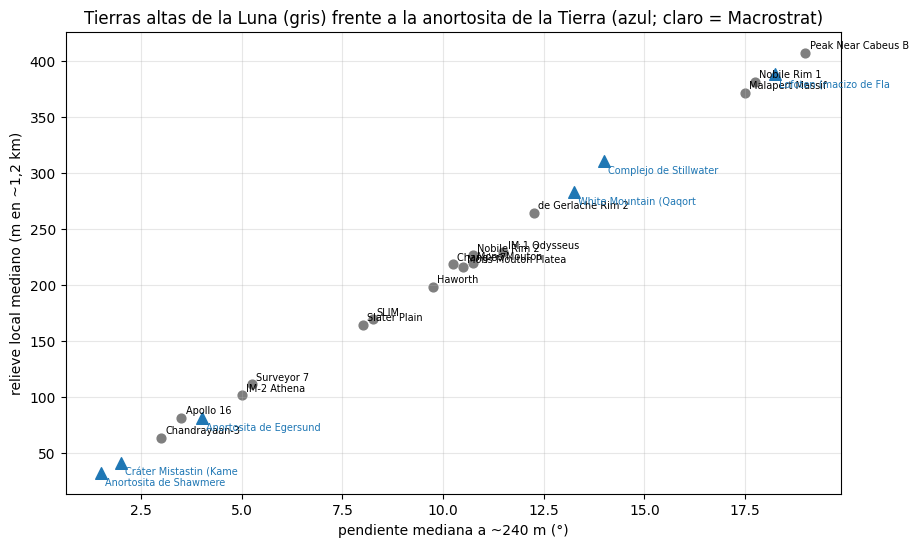

In [7]:
med = lambda h, bins: estadisticas(h, bins)
fig, ax = plt.subplots(figsize=(10, 6))
for s in altas.itertuples():
    if s.sitio_id in H_S:
        a, b = H_S[s.sitio_id]
        ax.scatter(med(a, BINS), med(b, BINS_REL), c="tab:gray", marker="o", s=40)
        ax.annotate(s.nombre[:18], (med(a, BINS), med(b, BINS_REL)), fontsize=7, xytext=(3, 3), textcoords="offset points")
for t in TIERRA.itertuples():
    if t.id in H_T:
        ax.scatter(t.pendiente_mediana, t.relieve_mediano_m, c="tab:blue" if t.origen == "ficha" else "tab:cyan", marker="^", s=70)
        ax.annotate(t.nombre.split(",")[0][:22], (t.pendiente_mediana, t.relieve_mediano_m), fontsize=7, color="tab:blue", xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("pendiente mediana a ~240 m (°)"); ax.set_ylabel("relieve local mediano (m en ~1,2 km)"); ax.grid(alpha=0.3)
ax.set_title("Tierras altas de la Luna (gris) frente a la anortosita de la Tierra (azul; claro = Macrostrat)"); plt.show()

## 6. Capa para la web y registro

In [8]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if not np.isfinite(v) else round(float(v), 3)
    if isinstance(v, np.integer): return int(v)
    if isinstance(v, np.bool_): return bool(v)
    return v

top3 = pares.sort_values("d_total").groupby("sitio_id").head(3)
salida = {"version": VERSION,
          "regla": {"umbral_topo": UMBRAL_TOPO, "umbral_geo": UMBRAL_GEO, "d_total": "media de d_geo y d_topo"},
          "sitios": {r["sitio_id"]: {**{k: limpio(v) for k, v in r.items() if k != "sitio_id"},
                                     "top3": [{k: limpio(p[k]) for k in ("id_t", "lugar", "verificacion", "d_geo", "d_topo", "d_total", "analogo_completo")}
                                              for p in top3[top3.sitio_id == r["sitio_id"]].to_dict("records")]}
                     for r in res.to_dict("records")},
          "tierra": {r["id"]: {k: limpio(v) if k != "composicion" else v for k, v in r.items() if k != "id"} for r in TIERRA.to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por sitio_id"}
json.dump(salida, open(f"{WEB}/anortosita.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, allow_nan=False)
TIERRA.assign(composicion=TIERRA.composicion.map(json.dumps)).to_csv(f"{RES}/anortosita_tierra.csv", index=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["anortosita"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/anortosita.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

registro = {"version": VERSION, "fecha": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="minutes"),
            "fuentes": {r.id: r.fuente for r in TIERRA.itertuples()}, "topografia": "Copernicus DEM GLO-30 (AWS)",
            "parametros": {"radio_km": RADIO_KM, "umbral_topo": UMBRAL_TOPO, "umbral_geo": UMBRAL_GEO, "macrostrat": USAR_MACROSTRAT},
            "metricas": {"sitios_tierras_altas": int(len(res)),
                         "completos_antes": int((res.antes_completo == "Sí").sum()),
                         "completos_ahora": int((res.analogo_completo == "Sí").sum()),
                         "lugares_tierra": int(len(TIERRA)), "lugares_macrostrat": int((TIERRA.origen == "macrostrat").sum()),
                         "mejor_d_geo_media": round(float(res.d_geo.mean()), 3), "mejor_d_topo_media": round(float(res.d_topo.mean()), 3)},
            "limitaciones": ["composición de los lugares de la Tierra estimada (ver nota_composicion)",
                             "círculo de 10 km: en Mistastin y en los fiordos, el agua aplanada se excluye",
                             "las tierras altas lunares están cubiertas de regolito y cráteres; los afloramientos de anortosita de la Tierra están erosionados por glaciares",
                             "las unidades de Macrostrat no están verificadas como análogo"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("✅ Exportado:", json.dumps(registro["metricas"], ensure_ascii=False, indent=1))

✅ Exportado: {
 "sitios_tierras_altas": 16,
 "completos_antes": 0,
 "completos_ahora": 10,
 "lugares_tierra": 6,
 "lugares_macrostrat": 0,
 "mejor_d_geo_media": 0.058,
 "mejor_d_topo_media": 0.211
}


## 7. Conclusiones

**La anortosita resuelve el hueco de geologia_v0.** Antes, ningún sitio de tierras altas tenía análogo completo (0 de 16), porque ninguna región candidata de la Tierra tenía anortosita y la mejor distancia geológica era 0,70. Con 6 afloramientos de anortosita, **10 de 16 sitios tienen análogo completo** (topografía ≤ 0,2 y geología ≤ 0,4), y **8 de 16 contando solo lugares verificados**.

**Cada tipo de terreno lunar tiene su anortosita en la Tierra:**

| Terreno lunar | Sitios con análogo completo | Análogo en la Tierra | Topografía |
|---|---|---|---|
| Macizos polares abruptos | Peak Near Cabeus B, Malapert Massif, Nobile Rim 1 | Lofoten, Noruega (relieve mediano 388 m, 18°) | 0,149–0,167 |
| Mesetas y bordes polares | Nobile Rim 2, Mons Mouton Plateau, de Gerlache Rim 2, IM-1, Mons Mouton | White Mountain, Groenlandia (283 m, 13°) | 0,149–0,171 |
| Llanuras de latitudes medias | Apollo 16, IM-2 | Egersund, Noruega (81 m, 4°); **candidato, no verificado** | 0,147–0,191 |

**Sin análogo completo (6): coincide la roca, no el terreno.** Haworth (0,243), Chang'e 7 (0,305), Slater Plain (0,342) y SLIM (0,425) con White Mountain; Chandrayaan-3 (0,201, justo en el límite) y Surveyor 7 (0,237) con Egersund.

**Lo que aporta cada lugar:**
- **Lofoten y White Mountain**: análogos de roca y de terreno. Sirven para entrenar movilidad y geología de campo en los sitios Artemis del polo sur.
- **Stillwater**: el terreno se parece a las mesetas polares (topografía ≤ 0,2 con 5 sitios), pero no pasa la geología (0,5) porque se supone mitad anortosita y mitad norita y gabro.
- **Mistastin y Shawmere**: demasiado llanos (relieve mediano de 32–41 m). Son análogos de **material**: fundido de impacto (Mistastin) y simulante de regolito OB-1 (Shawmere).

**Limitaciones**
- La composición de Lofoten (70 %) y Stillwater (50 %) es un supuesto: las fuentes no dan proporciones.
- Egersund solo aparece en una propuesta de tesis. Apollo 16 e IM-2 dependen de él.
- La coordenada de White Mountain se centró en la planta de la mina (informe DCE TR353). La mina está a ~4 km, dentro del círculo de 10 km. Las de Lofoten y Egersund son aproximadas.
- Topografía de la Tierra con Copernicus GLO-30 en un círculo de 10 km, sin lagos ni fiordos (Copernicus los aplana). La de la Luna viene de topografia_sitios_v2.
- Macrostrat no añadió unidades: solo se usan los 6 lugares de la ficha.

**Salidas**: `06_web/anortosita_v0/anortosita.json` (capa `anortosita` del manifest) y `04_resultados/anortosita_v0/`. Fuentes en la ficha de análogos (filas 34–39) y en la bibliografía.